# Initialisation

In [ ]:
!if [ -d cs294-158-ssl ]; then rm -Rf cs294-158-ssl; fi
!git clone https://github.com/ckurtz/cs294-158-ssl
!pip install cs294-158-ssl/

import os
os.chdir('cs294-158-ssl')

In [ ]:
!wget https://camille-kurtz.com/teaching/data.zip
!unzip -qq data.zip
!rm data.zip

In [ ]:
!wget https://camille-kurtz.com/teaching/results.zip
!unzip -qq results.zip
!rm results.zip

In [ ]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, evaluate_classifier, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

# Question 3
*Proposer et coder un script permettant de comparer les performances de classification de l’ensemble des modèles sur un même tableau / ou graphique.*

In [ ]:
def get_top1_top5_accuracy(model: str, dataset = 'cifar10'):
  # Get accuracies of one specific model on a given dataset
  model, linear_classifier, train_loader, test_loader = load_model_and_data(model, dataset)
  train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
  test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

  return train_acc1, train_acc5, test_acc1, test_acc5

def get_models_accuracies(models: list[str], dataset = 'cifar10'):
  # Get accuracies for several models
  train_acc1_list, train_acc5_list = list(), list()
  test_acc1_list, test_acc5_list = list(), list()

  for model in models:
    print(f"{model}...")
    train_acc1, train_acc5, test_acc1, test_acc5 = get_top1_top5_accuracy(model, dataset)
    train_acc1_list.append(train_acc1)
    train_acc5_list.append(train_acc5)
    test_acc1_list.append(test_acc1)
    test_acc5_list.append(test_acc5)

  return train_acc1_list, train_acc5_list, test_acc1_list, test_acc5_list

In [ ]:
import matplotlib.pyplot as plt

def plot_accuracies(train_acc1_list, train_acc5_list, test_acc1_list, test_acc5_list, names: list[str], title: str):
  # Plot Top1 and Top5 accuracies for several models
  fig, axes = plt.subplots(2, 2, figsize=(8, 5))

  # Title
  fig.suptitle(title)

  # Figure 1 (Top 1 accuracy)
  bars1 = axes[0,0].bar(names, train_acc1_list, color="steelblue")
  axes[0,0].set_title("Train Top 1")
  axes[0,0].set_ylabel("Accuracy")
  axes[0,0].bar_label(bars1, label_type="center")

  # Figure 2 (Top 5 accuracy)
  bars2 = axes[0,1].bar(names, train_acc5_list, color="orange")
  axes[0,1].set_title("Train Top 5")
  axes[0,1].set_ylabel("Accuracy")
  axes[0,1].bar_label(bars2, label_type="center")

  # Figure 3 (Train Top 1)
  bars3 = axes[1,0].bar(names, test_acc1_list, color="steelblue")
  axes[1,0].set_title("Test Top 1")
  axes[1,0].set_ylabel("Accuracy")
  axes[1,0].bar_label(bars3, label_type="center")

  # Figure 3 (Train Top 1)
  bars4 = axes[1,1].bar(names, test_acc5_list, color="orange")
  axes[1,1].set_title("Test Top 5")
  axes[1,1].set_ylabel("Accuracy")
  axes[1,1].bar_label(bars4, label_type="center")

  plt.tight_layout()
  plt.show()

In [ ]:
models = ['context_encoder', 'rotation', 'simclr']
dataset = 'cifar10'

train_acc1_list, train_acc5_list, test_acc1_list, test_acc5_list = get_models_accuracies(models, dataset)

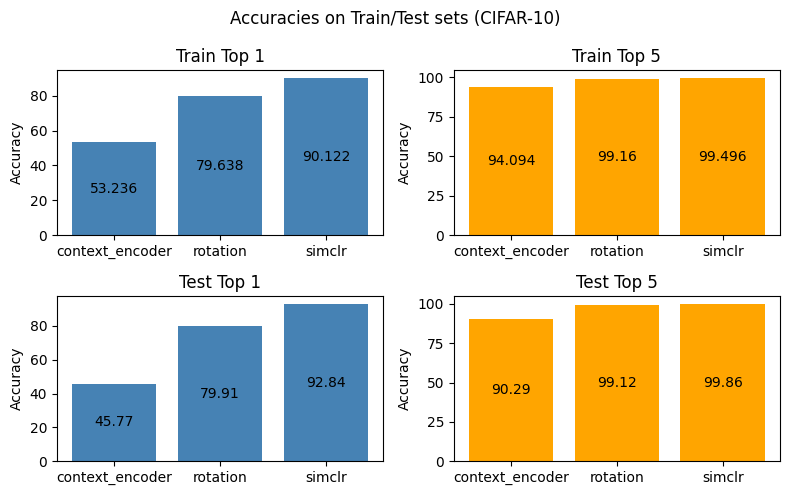

In [ ]:
plot_accuracies(train_acc1_list, train_acc5_list, test_acc1_list, test_acc5_list, models, "Accuracies on Train/Test sets (CIFAR-10)")

# Question 4
*Effectuer la comparaison sur un autre jeu de données de votre choix (du même ordre de grandeur que CIFAR10).*

# Question 5
*En vous appuyant sur la librairie existante, implémenter la tâche prétexte
consistant à apprendre au modèle à prédire la position relative d’un patch de
l’image relativement à un patch requête (diapo 18 du cours et figure), voir
également : https://arxiv.org/pdf/1505.05192.pdf*

In [ ]:
import random
import torch

def extract_patches(images, patch_size=8, gap=2):
    """
    images: (B, C, H, W)

    Returns:
        patch_a: (B, C, P, P)
        patch_b: (B, C, P, P)
        targets: integers in [0, 7]
    """
    B, C, H, W = images.shape
    S = patch_size + gap

    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        ( 0, -1),          ( 0, 1),
        ( 1, -1), ( 1, 0), ( 1, 1)
    ]

    patches_a = []
    patches_b = []
    targets = []

    for i in range(B):

        # Choose one of the 8 relative positions
        label = random.randrange(8)
        dy, dx = directions[label]

        # Choose a valid reference patch location
        valid_y = list(range(
            max(0, -dy * S),
            min(H - patch_size, H - patch_size - dy * S) + 1
        ))
        valid_x = list(range(
            max(0, -dx * S),
            min(W - patch_size, W - patch_size - dx * S) + 1
        ))

        y = random.choice(valid_y)
        x = random.choice(valid_x)

        # Extract the two patches
        patch_a = images[i, :, y:y+patch_size, x:x+patch_size]

        y_b = y + dy * S
        x_b = x + dx * S

        patch_b = images[i, :, y_b:y_b+patch_size, x_b:x_b+patch_size]

        patches_a.append(patch_a)
        patches_b.append(patch_b)
        targets.append(label)

    return (
        torch.stack(patches_a),
        torch.stack(patches_b),
        torch.tensor(targets, device=images.device)
    )

In [ ]:
from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm
import torch
import torch.nn as nn
import torch.nn.functional as F

class RelativePosition(nn.Module):

    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset=None, n_classes=8):
        super().__init__()

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.encoder = resnet
            self.latent_dim = 2048 # ResNet50 end

        self.classifier = nn.Sequential(
            # entry : 2 concatenated vectors
            nn.Linear(2 * self.latent_dim, 512),
            nn.ReLU(),
            nn.Linear(512, n_classes)
        )

    def forward(self, images):

        # Generate pairs of patches, and corresponding labels
        if dataset == 'cifar10':
          patch_a, patch_b, targets = extract_patches(
              images,
              patch_size=8, # CIFAR10 : 32x32 images
              gap=2
          )

        # Encode each patch
        z_a = self.encode(patch_a)
        z_b = self.encode(patch_b)

        # Concatenate the two vectors, predict a label
        z = torch.cat([z_a, z_b], dim=1)
        logits = self.classifier(z)

        # Loss and accuracy
        loss = F.cross_entropy(logits, targets)
        predictions = logits.argmax(dim=1) # select label with maximum value
        acc = (predictions == targets).float().mean() * 100

        return dict(
            Loss=loss,
            Acc1=acc
        ), z_a

    def encode(self, images):
        return self.encoder(images)

# Question 6
Évaluer les performances relativement aux modèles entraînés via les autres tâches prétextes sur CIFAR10 et un autre jeu de données de votre choix